In [ ]:
# ==========================================
# STEP 1
# IMPORT LIBRARIES
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==========================================
# STEP 1
# IMPORT LIBRARIES
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

import os
import joblib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import rankdata

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.model_selection import (
    GroupShuffleSplit,
    train_test_split
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print(tf.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2.20.0


In [ ]:
#Fix Random Seeds

# ==========================================
# REPRODUCIBILITY
# ==========================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [ ]:
# ==========================================
# STEP 2
# CREATE PROJECT FOLDERS
# ==========================================

base_path="/content/drive/MyDrive/RE2/LSTM_Model"

folders=[

    "figures",

    "tables",

    "models",

    "checkpoints",

    "history",

    "external_validation"

]

for f in folders:

    os.makedirs(

        os.path.join(base_path,f),

        exist_ok=True

    )

print("Folders Created Successfully")

Folders Created Successfully


In [ ]:
# ==========================================
# STEP 3
# LOAD DATASET
# ==========================================

dataset_path="/content/drive/MyDrive/RE2/Dataset.csv"

df=pd.read_csv(dataset_path)

print(df.shape)

df.head()

(1552210, 44)


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


In [ ]:
# ==========================================
# STEP 4
# DROP COLUMN
# ==========================================

if "Unnamed: 0" in df.columns:

    df=df.drop(columns=["Unnamed: 0"])

print(df.shape)

(1552210, 43)


In [ ]:
#Sort Patient-wise
df = df.sort_values(
    ["Patient_ID","Hour"]
).reset_index(drop=True)

In [ ]:
#Create 6-hour Early Prediction Target
# ==========================================
# EARLY PREDICTION TARGET
# ==========================================

df["SepsisLabel_e"] = (
    df.groupby("Patient_ID")["SepsisLabel"]
      .shift(-6)
)

df = df.dropna(
    subset=["SepsisLabel_e"]
)

df["SepsisLabel_e"] = df["SepsisLabel_e"].astype(int)

print(df.shape)

(1310194, 44)


In [ ]:
#Dataset Summary
print("Rows :",len(df))
print("Patients :",df.Patient_ID.nunique())

print(df.SepsisLabel_e.value_counts())

Rows : 1310194
Patients : 40336
SepsisLabel_e
0    1285791
1      24403
Name: count, dtype: int64


In [ ]:
#Save Dataset Summary
summary = pd.DataFrame({

    "Rows":[len(df)],
    "Patients":[df.Patient_ID.nunique()],
    "Positive":[df.SepsisLabel_e.sum()],
    "Negative":[
        len(df)-df.SepsisLabel_e.sum()
    ]

})

summary.to_csv(

    base_path+
    "/tables/Dataset_Summary.csv",

    index=False
)

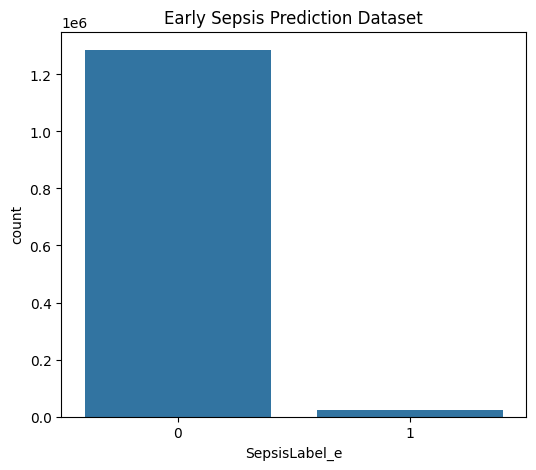

In [ ]:
#Class Distribution Figure
plt.figure(figsize=(6,5))

sns.countplot(
    x="SepsisLabel_e",
    data=df
)

plt.title("Early Sepsis Prediction Dataset")

plt.savefig(

    base_path+
    "/figures/Class_Distribution.png",

    dpi=300,
    bbox_inches="tight"

)

plt.show()

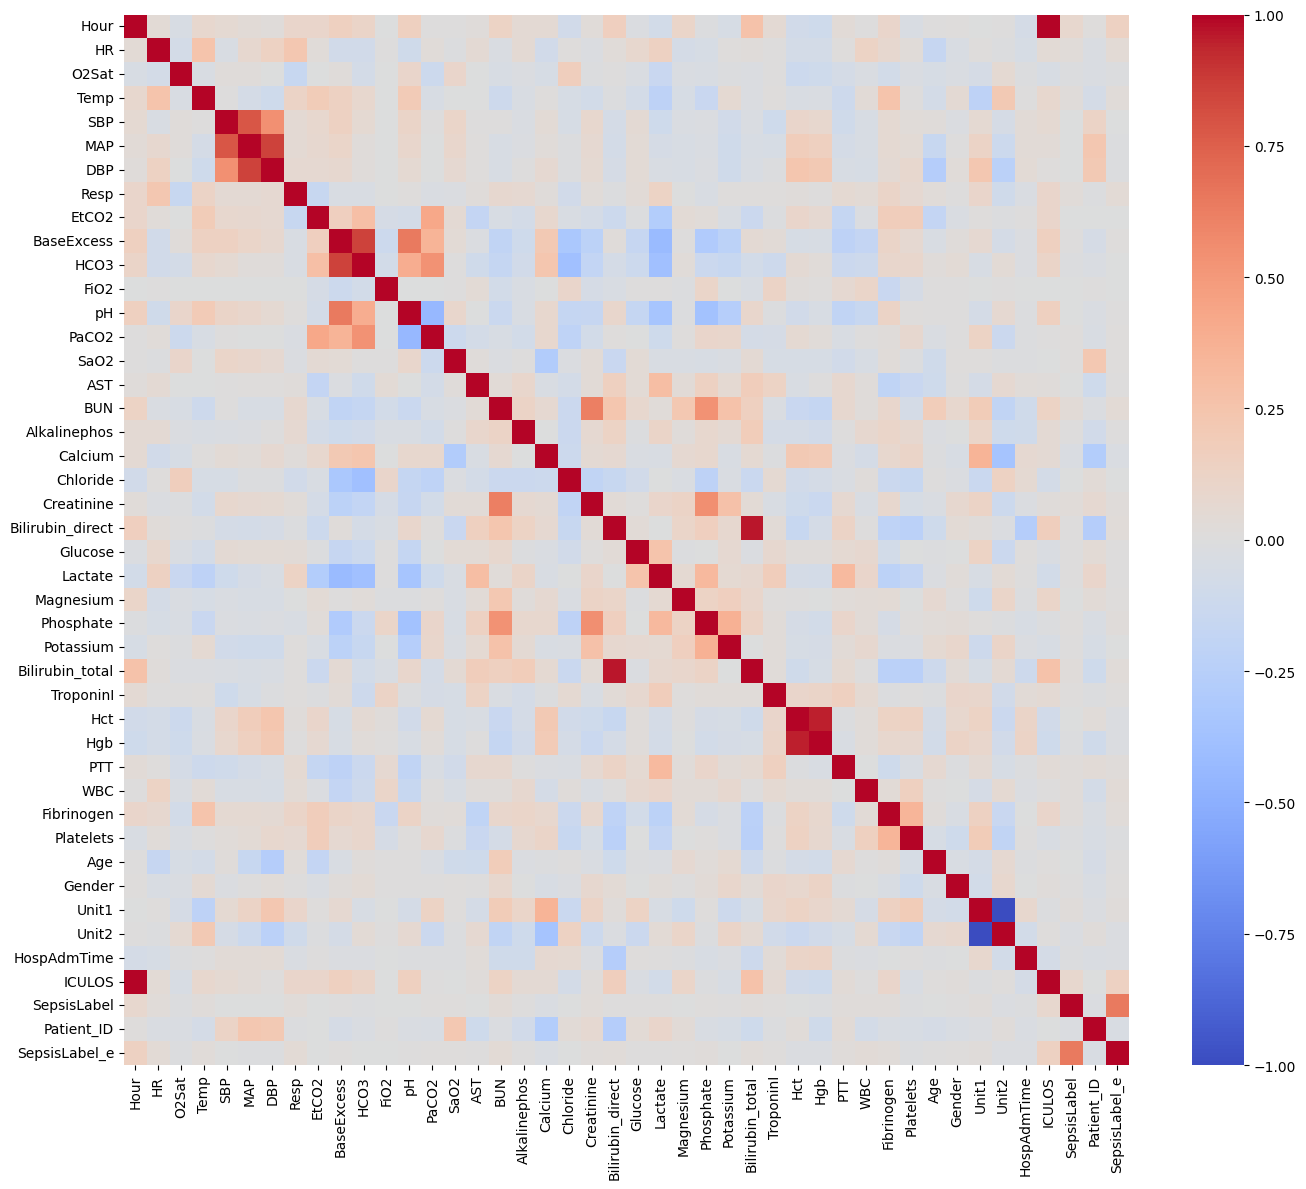

In [ ]:
# ==========================================
# STEP 10
# HEATMAP
# ==========================================

plt.figure(figsize=(14,12))

sns.heatmap(

    df.corr(numeric_only=True),

    cmap="coolwarm",

    annot=False

)

plt.tight_layout()

plt.savefig(

    base_path+"/figures/Correlation_Heatmap.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

In [ ]:
#PREPROCESSING
# ==========================================
# STEP 2.1
# MISSING VALUE ANALYSIS
# ==========================================

missing_percent = df.isnull().mean() * 100

missing_percent = missing_percent.sort_values(
    ascending=False
)

print(missing_percent)

missing_percent.to_csv(
    base_path +
    "/tables/Missing_Percentage.csv"
)

Bilirubin_direct    99.793389
Fibrinogen          99.279420
TroponinI           98.967329
Bilirubin_total     98.393520
Alkalinephos        98.268959
AST                 98.251633
Lactate             97.078219
PTT                 96.835202
SaO2                96.237427
EtCO2               95.979756
Phosphate           95.744523
HCO3                95.568290
Chloride            95.188422
BaseExcess          94.090417
PaCO2               93.931662
Calcium             93.735737
Platelets           93.684599
Creatinine          93.546757
Magnesium           93.347397
WBC                 93.198641
BUN                 92.726344
pH                  92.486151
Hgb                 92.152307
FiO2                90.987213
Hct                 90.588035
Potassium           90.115510
Glucose             82.177754
Temp                65.524113
Unit2               39.555822
Unit1               39.555822
DBP                 30.278340
Resp                14.976103
SBP                 13.795056
O2Sat     

In [ ]:
#Create Missing Indicators
# ==========================================
# STEP 2.2
# MISSING INDICATORS
# ==========================================

missing_cols = [

    col

    for col in df.columns

    if df[col].isnull().mean() > 0.05

]

for col in missing_cols:

    df[col + "_missing"] = (
        df[col]
        .isnull()
        .astype(int)
    )

print("Missing Indicators Added :",len(missing_cols))

Missing Indicators Added : 36


In [ ]:
#Drop Columns with >25% Missing
# ==========================================
# STEP 2.3
# DROP HIGH MISSING FEATURES
# ==========================================

keep_columns = df.columns[
    df.isnull().mean() < 0.25
]

df = df[keep_columns]

print(df.shape)

print(df.columns.tolist())

(1310194, 49)
['Hour', 'HR', 'O2Sat', 'SBP', 'MAP', 'Resp', 'Age', 'Gender', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID', 'SepsisLabel_e', 'HR_missing', 'O2Sat_missing', 'Temp_missing', 'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing', 'EtCO2_missing', 'BaseExcess_missing', 'HCO3_missing', 'FiO2_missing', 'pH_missing', 'PaCO2_missing', 'SaO2_missing', 'AST_missing', 'BUN_missing', 'Alkalinephos_missing', 'Calcium_missing', 'Chloride_missing', 'Creatinine_missing', 'Bilirubin_direct_missing', 'Glucose_missing', 'Lactate_missing', 'Magnesium_missing', 'Phosphate_missing', 'Potassium_missing', 'Bilirubin_total_missing', 'TroponinI_missing', 'Hct_missing', 'Hgb_missing', 'PTT_missing', 'WBC_missing', 'Fibrinogen_missing', 'Platelets_missing', 'Unit1_missing', 'Unit2_missing']


In [ ]:
# ==========================================
# STEP 2.4
# GENDER ENCODING
# ==========================================

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Gender"] = encoder.fit_transform(
    df["Gender"].astype(str)
)

In [ ]:
# ==========================================
# STEP 2.5
# FEATURE TARGET SPLIT
# ==========================================

X = df.drop(

    columns=[

        "SepsisLabel",
        "SepsisLabel_e",
        "Patient_ID"

    ]

)

y = df["SepsisLabel_e"]

groups = df["Patient_ID"]

In [ ]:
# ==========================================
# STEP 2.6
# PATIENT WISE SPLIT
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(

    test_size=0.20,

    random_state=42

)

train_idx, test_idx = next(

    gss.split(

        X,

        y,

        groups

    )

)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print(X_train.shape)
print(X_test.shape)

(1047605, 46)
(262589, 46)


In [ ]:
#Save Patient IDs
groups_train.to_csv(

    base_path+
    "/tables/train_patient_ids.csv",

    index=False

)

groups_test.to_csv(

    base_path+
    "/tables/test_patient_ids.csv",

    index=False

)

In [ ]:
# ==========================================
# STEP 17
# VALIDATION SPLIT
# ==========================================

gss2 = GroupShuffleSplit(

    test_size=0.20,

    random_state=42

)

train2,val_idx = next(

    gss2.split(

        X_train,

        y_train,

        groups_train

    )

)

X_val = X_train.iloc[val_idx].copy()

y_val = y_train.iloc[val_idx].copy()

groups_val = groups_train.iloc[val_idx]

X_train = X_train.iloc[train2].copy()

y_train = y_train.iloc[train2].copy()

groups_train = groups_train.iloc[train2]

print(X_train.shape)

print(X_val.shape)

print(X_test.shape)

(837503, 46)
(210102, 46)
(262589, 46)


In [ ]:
# ==========================================
# STEP 18
# MEDIAN IMPUTATION
# ==========================================

imputer = SimpleImputer(

    strategy="median"

)

X_train = pd.DataFrame(

    imputer.fit_transform(X_train),

    columns=X.columns

)

X_val = pd.DataFrame(

    imputer.transform(X_val),

    columns=X.columns

)

X_test = pd.DataFrame(

    imputer.transform(X_test),

    columns=X.columns

)

joblib.dump(

    imputer,

    base_path+"/checkpoints/imputer.pkl"

)

print("Imputer Saved")

Imputer Saved


In [ ]:
# ==========================================
# STEP 19
# LOG TRANSFORMATION
# ==========================================

log_cols = [

    "MAP",

    "BUN",

    "Creatinine",

    "Glucose",

    "WBC",

    "Platelets"

]

for col in log_cols:

    if col in X_train.columns:

        X_train[col] = np.log1p(

            X_train[col]

        )

        X_val[col] = np.log1p(

            X_val[col]

        )

        X_test[col] = np.log1p(

            X_test[col]

        )

print("Log Transform Complete")

Log Transform Complete


In [ ]:
# ==========================================
# STEP 20
# STANDARD SCALER
# ==========================================

scaler = StandardScaler()

X_train = pd.DataFrame(

    scaler.fit_transform(X_train),

    columns=X_train.columns

)

X_val = pd.DataFrame(

    scaler.transform(X_val),

    columns=X_val.columns

)

X_test = pd.DataFrame(

    scaler.transform(X_test),

    columns=X_test.columns

)

joblib.dump(

    scaler,

    base_path+"/checkpoints/scaler.pkl"

)

print("Scaler Saved")

Scaler Saved


In [ ]:
# ==========================================
# STEP 21
# SAVE PROCESSED TABLES
# ==========================================

X_train.to_csv(

    base_path+"/tables/X_train.csv",

    index=False

)

X_val.to_csv(

    base_path+"/tables/X_val.csv",

    index=False

)

X_test.to_csv(

    base_path+"/tables/X_test.csv",

    index=False

)

y_train.to_csv(

    base_path+"/tables/y_train.csv",

    index=False

)

y_val.to_csv(

    base_path+"/tables/y_val.csv",

    index=False

)

y_test.to_csv(

    base_path+"/tables/y_test.csv",

    index=False

)

print("All Files Saved")

All Files Saved


In [ ]:
#12-hour window is the better choice for your research because you're predicting sepsis 6 hours early.
#Sequence Length
# ==========================================
# STEP 22
# LSTM WINDOW SIZE
# ==========================================

SEQUENCE_LENGTH = 12

print("Sequence Length :", SEQUENCE_LENGTH)

Sequence Length : 12


In [ ]:
# ==========================================
# STEP 23
# CREATE 12 HR LSTM SEQUENCES
# ==========================================

def create_sequences(X, y, groups, seq_len=12):

    X_seq = []
    y_seq = []

    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)
    groups = groups.reset_index(drop=True)

    unique_patients = groups.unique()

    for patient in unique_patients:

        idx = np.where(groups == patient)[0]

        patient_X = X.iloc[idx].values
        patient_y = y.iloc[idx].values

        if len(patient_X) < seq_len:
            continue

        for i in range(len(patient_X) - seq_len + 1):

            X_seq.append(
                patient_X[i:i+seq_len]
            )

            y_seq.append(
                patient_y[i+seq_len-1]
            )

    return np.array(X_seq), np.array(y_seq)

In [ ]:
# ==========================================
# STEP 24
# Generate TRAIN SEQUENCES
# ==========================================

X_train_seq, y_train_seq = create_sequences(

    X_train,

    y_train,

    groups_train,

    SEQUENCE_LENGTH

)

print(X_train_seq.shape)

print(y_train_seq.shape)

(562121, 12, 46)
(562121,)


In [ ]:
# ==========================================
# STEP 25
# GENERATE VALIDATION SEQUENCES
# ==========================================

X_val_seq, y_val_seq = create_sequences(

    X_val,

    y_val,

    groups_val,

    SEQUENCE_LENGTH

)

print(X_val_seq.shape)

print(y_val_seq.shape)

(141366, 12, 46)
(141366,)


In [ ]:
# ==========================================
# STEP 26
# TEST SEQUENCES
# ==========================================

X_test_seq, y_test_seq = create_sequences(

    X_test,

    y_test,

    groups_test,

    SEQUENCE_LENGTH

)

print(X_test_seq.shape)

print(y_test_seq.shape)

(176536, 12, 46)
(176536,)


In [ ]:
# ==========================================
# STEP 27
# FINAL SHAPES
# ==========================================

print("Train :", X_train_seq.shape)

print("Validation :", X_val_seq.shape)

print("Test :", X_test_seq.shape)

Train : (562121, 12, 46)
Validation : (141366, 12, 46)
Test : (176536, 12, 46)


In [ ]:
# ==========================================
# STEP 28
# SAVE NUMPY ARRAYS
# ==========================================

np.save(

    base_path+"/tables/X_train_seq.npy",

    X_train_seq

)

np.save(

    base_path+"/tables/X_val_seq.npy",

    X_val_seq

)

np.save(

    base_path+"/tables/X_test_seq.npy",

    X_test_seq

)

np.save(

    base_path+"/tables/y_train_seq.npy",

    y_train_seq

)

np.save(

    base_path+"/tables/y_val_seq.npy",

    y_val_seq

)

np.save(

    base_path+"/tables/y_test_seq.npy",

    y_test_seq

)

print("Sequences Saved Successfully")

Sequences Saved Successfully


In [ ]:
# ==========================================
# STEP 13 — BUILD LSTM MODEL
# ==========================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

model = Sequential()

# -------------------------
# LSTM Layer 1
# -------------------------
model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(X_train.shape[1], 1)
    )
)

model.add(BatchNormalization())
model.add(Dropout(0.3))

# -------------------------
# LSTM Layer 2
# -------------------------
model.add(
    LSTM(
        32,
        return_sequences=False
    )
)

model.add(BatchNormalization())
model.add(Dropout(0.3))

# -------------------------
# Dense Layers
# -------------------------
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(1, activation='sigmoid'))

# -------------------------
# Compile
# -------------------------
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 46, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 46, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,241 (118.13 KB)

 Trainable params: 30,049 (117.38 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# ==========================================
# CALLBACKS
# ==========================================

checkpoint = ModelCheckpoint(
    base_path + "/LSTM_Model/models/best_lstm.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_auc",
    patience=5,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

In [ ]:
# ==========================================
# TRAIN MODEL
# ==========================================

history = model.fit(

    X_train,

    y_train,

    validation_data=(X_val, y_val),

    epochs=25,

    batch_size=256,

    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ],

    verbose=1

)

Epoch 1/25
3272/3272 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9554 - auc: 0.5020 - loss: 0.1550
Epoch 1: val_auc improved from None to 0.65237, saving model to /content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/models/best_lstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/models/best_lstm.keras
3272/3272 ━━━━━━━━━━━━━━━━━━━━ 55s 14ms/step - accuracy: 0.9753 - auc: 0.5295 - loss: 0.1184 - val_accuracy: 0.9809 - val_auc: 0.6524 - val_loss: 0.0923 - learning_rate: 0.0010
Epoch 2/25
3269/3272 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9810 - auc: 0.5709 - loss: 0.0990
Epoch 2: val_auc improved from 0.65237 to 0.73701, saving model to /content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/models/best_lstm.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/models/best_lstm.keras
3272/3272 ━━━━━━━━━━━━━━━━━━━━ 45s 14ms/step - accuracy: 0.9811 - auc: 0.6261 - loss: 0.0939 - val_accuracy: 0.9809 - val_auc: 0

In [ ]:
print("NaN in y_prob:", np.isnan(y_prob).sum())

print("NaN in X_train_seq:", np.isnan(X_train_seq).sum())

print("NaN in X_test_seq:", np.isnan(X_test_seq).sum())

NaN in y_prob: 25632
NaN in X_train_seq: 0
NaN in X_test_seq: 0


In [ ]:
import numpy as np

for layer in model.layers:

    weights = layer.get_weights()

    for i, w in enumerate(weights):

        if np.isnan(w).any():

            print(layer.name, "Weight", i, "contains NaN")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/models/best_lstm.keras"
)

y_prob = model.predict(X_test_seq).ravel()

print(np.isnan(y_prob).sum())

5517/5517 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step
0


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    auc
)

# Prediction
y_prob = model.predict(X_test_seq).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test_seq, y_pred)
precision = precision_score(y_test_seq, y_pred, zero_division=0)
recall = recall_score(y_test_seq, y_pred, zero_division=0)
f1 = f1_score(y_test_seq, y_pred, zero_division=0)
roc = roc_auc_score(y_test_seq, y_prob)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test_seq,
    y_prob
)

pr_auc = auc(recall_curve, precision_curve)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC AUC  :", roc)
print("PR AUC   :", pr_auc)

print(classification_report(y_test_seq, y_pred))

5517/5517 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step
Accuracy : 0.9800380658902433
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC AUC  : 0.5305536411717212
PR AUC   : 0.02051254673409749
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    173012
           1       0.00      0.00      0.00      3524

    accuracy                           0.98    176536
   macro avg       0.49      0.50      0.49    176536
weighted avg       0.96      0.98      0.97    176536



OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/RE2/LSTM_Model/LSTM_Model/tables'

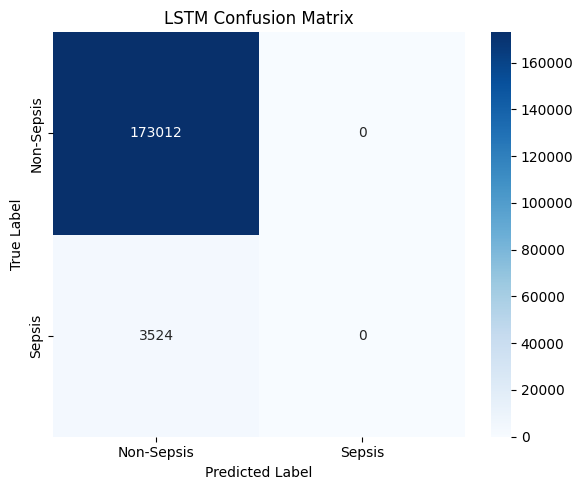

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_seq, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Sepsis","Sepsis"],
    yticklabels=["Non-Sepsis","Sepsis"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("LSTM Confusion Matrix")

plt.tight_layout()

plt.savefig(
    base_path+"/figures/LSTM_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

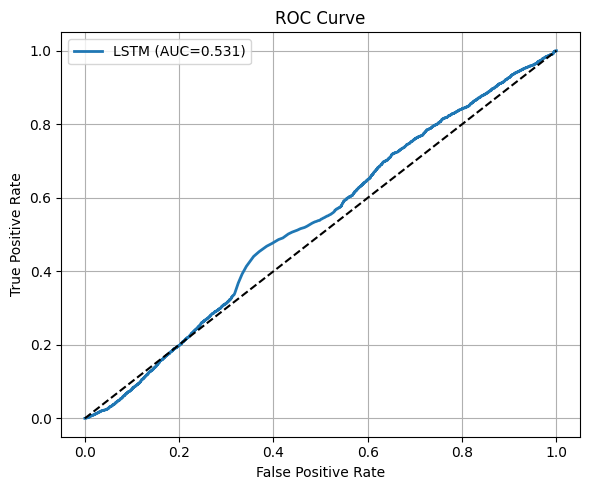

In [ ]:
#ROC Curve (300 DPI)
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test_seq, y_prob)

roc_auc = auc(fpr,tpr)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"LSTM (AUC={roc_auc:.3f})"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    base_path+"/figures/LSTM_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

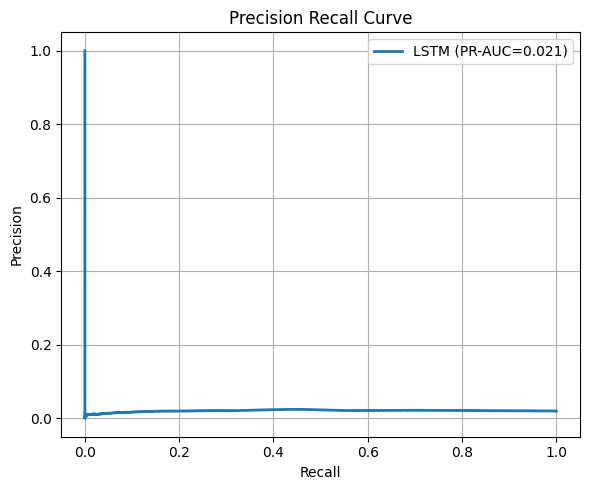

In [ ]:
#Precision Recall Curve (300 DPI)
precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_test_seq,
    y_prob
)

pr_auc = auc(recall_curve, precision_curve)

plt.figure(figsize=(6,5))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"LSTM (PR-AUC={pr_auc:.3f})"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision Recall Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    base_path+"/figures/LSTM_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Threshold Optimization

from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

results=[]

for th in np.arange(0.1,0.95,0.05):

    pred=(y_prob>=th).astype(int)

    results.append({

        "Threshold":round(th,2),

        "Accuracy":accuracy_score(y_test_seq,pred),

        "Precision":precision_score(
            y_test_seq,
            pred,
            zero_division=0
        ),

        "Recall":recall_score(
            y_test_seq,
            pred,
            zero_division=0
        ),

        "F1":f1_score(
            y_test_seq,
            pred,
            zero_division=0
        )

    })

threshold_df=pd.DataFrame(results)

print(threshold_df)

threshold_df.to_csv(

    base_path+"/tables/LSTM_Threshold_Optimization.csv",

    index=False
)

    Threshold  Accuracy  Precision  Recall   F1
0        0.10  0.979687        0.0     0.0  0.0
1        0.15  0.980027        0.0     0.0  0.0
2        0.20  0.980038        0.0     0.0  0.0
3        0.25  0.980038        0.0     0.0  0.0
4        0.30  0.980038        0.0     0.0  0.0
5        0.35  0.980038        0.0     0.0  0.0
6        0.40  0.980038        0.0     0.0  0.0
7        0.45  0.980038        0.0     0.0  0.0
8        0.50  0.980038        0.0     0.0  0.0
9        0.55  0.980038        0.0     0.0  0.0
10       0.60  0.980038        0.0     0.0  0.0
11       0.65  0.980038        0.0     0.0  0.0
12       0.70  0.980038        0.0     0.0  0.0
13       0.75  0.980038        0.0     0.0  0.0
14       0.80  0.980038        0.0     0.0  0.0
15       0.85  0.980038        0.0     0.0  0.0
16       0.90  0.980038        0.0     0.0  0.0


In [ ]:
print("Minimum :", y_prob.min())
print("Maximum :", y_prob.max())
print("Mean    :", y_prob.mean())

print(np.percentile(y_prob, [0, 1, 5, 25, 50, 75, 95, 99, 100]))

print("Predicted positives @0.5 :", np.sum(y_prob >= 0.5))
print("Predicted positives @0.3 :", np.sum(y_prob >= 0.3))
print("Predicted positives @0.1 :", np.sum(y_prob >= 0.1))
print("Predicted positives @0.01:", np.sum(y_prob >= 0.01))

Minimum : 0.0038236647
Maximum : 0.16386138
Mean    : 0.0344934
[0.00382366 0.01691005 0.02115878 0.03324599 0.03459449 0.03553167
 0.04585849 0.06018965 0.16386138]
Predicted positives @0.5 : 0
Predicted positives @0.3 : 0
Predicted positives @0.1 : 62
Predicted positives @0.01: 176471


In [ ]:
#Best Threshold
precision_curve, recall_curve, thresholds = precision_recall_curve(

    y_test_seq,

    y_prob

)

f1_scores=(

    2*precision_curve[:-1]*recall_curve[:-1]

)/(

    precision_curve[:-1]+recall_curve[:-1]+1e-10

)

best_idx=np.argmax(f1_scores)

best_threshold=thresholds[best_idx]

print("Best Threshold =",best_threshold)

print("Best F1 =",f1_scores[best_idx])

Best Threshold = 0.03459464
Best F1 = 0.04633112423625698


In [ ]:
#Evaluation using Best Threshold
best_pred=(y_prob>=best_threshold).astype(int)

print("Accuracy :",accuracy_score(y_test_seq,best_pred))

print("Precision:",precision_score(
    y_test_seq,
    best_pred,
    zero_division=0
))

print("Recall :",recall_score(
    y_test_seq,
    best_pred,
    zero_division=0
))

print("F1 :",f1_score(
    y_test_seq,
    best_pred,
    zero_division=0
))

Accuracy : 0.638079485204151
Precision: 0.024451726745651627
Recall : 0.44040862656072643
F1 : 0.046331124246223654


In [ ]:
#95% Confidence Interval (ROC-AUC)
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score
import numpy as np

boot_scores=[]

for i in range(1000):

    idx=resample(

        np.arange(len(y_test_seq)),

        replace=True

    )

    if len(np.unique(y_test_seq[idx]))<2:

        continue

    score=roc_auc_score(

        y_test_seq[idx],

        y_prob[idx]

    )

    boot_scores.append(score)

lower=np.percentile(boot_scores,2.5)

upper=np.percentile(boot_scores,97.5)

print("ROC-AUC =",roc_auc_score(y_test_seq,y_prob))

print("95% CI =",lower,upper)

ROC-AUC = 0.5305536411717212
95% CI = 0.5215051167324001 0.5394933888601938
